## Introduzione al progetto
 
 I mercati finanziari generano ogni giorno una grande quantità di dati, come i prezzi di apertura, chiusura, volumi di scambio e
 variazioni percentuali. Analizzare questi dati manualmente è complesso, ma le tecniche di Machine Learning permettono di individuare
 pattern  e relazioni utili per effettuare previsioni.

 L'obiettivo di questo progetto è applicare algoritmi di Machine Learning per predire la direzione del prezzo di un'azione,
 utilizzando dati storici reali. In particolare, il modello che cercherà di prevedere se il prezzo di chiusura di un'azione aumenterà
 o diminuirà nel giorno successivo, trasformando il problema in un task di classificazione binaria.

 Per svolgere questa analisi verranno utilizzati dati finanziari storici scaricati tramite la libreria Python /yfinance.
 Successivamente, i dati verranno preprocessati per creare le feature di input e la variabile target. Verrano quindi addrestati
 e confrontati diversi algoritmi di Machine Learning, tra cui Logistic Regression e Random Forest.

 Infine, le performance dei modelli veranno valutate utilizzando metriche di classificazione come l'accuracy e la confusion matrix, 
 al fine di determinare quale algoritmo sia più efficace nella predizione della direzione del prezzo azionario.

 Questo progetto dimostra come le tecniche di Machine Learning possono essere applicate a problemi reali nel contesto finanziario, evidenziando sia le potenzialità che i limiti di questi approcci.

In [1]:
!pip install yfinance 
!pip install matplotlib scikit-learn pandas numpy
!pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Import delle librerie necessarie
import yfinance as yf
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

## Caricamento dei dati

I dati utilizzati nel progetto sono stati scaricati tramite la libreria yfinance, che consente di ottenere serie storiche finanziarie da Yahoo Finance.

In particolare, è stato selezionato il titolo Apple (AAPL) nel periodo compreso tra il 2018 e il 2024. Il dataset include informazioni giornaliere come prezzo di apertura, massimo, minimo, chiusura e volume.

In [3]:
# Scarico dati azioni Apple

data = yf.download("AAPL", start="2018-01-01", end="2024-01-01")

#Mostro le prime righe

(data.head())

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2018-01-02,40.232380,40.241724,39.531711,39.741914,102223600
2018-01-03,40.225376,40.767228,40.162319,40.295444,118071600
2018-01-04,40.412212,40.514978,40.190335,40.297769,89738400
2018-01-05,40.872314,40.958729,40.416881,40.507968,94640000
2018-01-08,40.720516,41.014796,40.622419,40.720516,82271200


## Espolrazione del dataset

In questa fase viene effettuata un’analisi preliminare del dataset, osservando la struttura dei dati, il numero di osservazioni e alcune statistiche descrittive.

Questa analisi permette di comprendere meglio le caratteristiche delle variabili e individuare eventuali problemi nei dati.

In [4]:
#Dimensioni del dataset
print("Shape: ", data.shape)

#Info colonne
data.info()

#Statistiche base
data.describe()

Shape:  (1509, 5)
<class 'pandas.DataFrame'>
DatetimeIndex: 1509 entries, 2018-01-02 to 2023-12-29
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, AAPL)   1509 non-null   float64
 1   (High, AAPL)    1509 non-null   float64
 2   (Low, AAPL)     1509 non-null   float64
 3   (Open, AAPL)    1509 non-null   float64
 4   (Volume, AAPL)  1509 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 70.7 KB


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
count,1509.000000,1509.000000,1509.000000,1509.000000,1.509000e+03
mean,107.531711,108.656291,106.294922,107.432027,1.073284e+08
std,50.795831,51.268348,50.269725,50.754968,5.513287e+07
min,33.707924,34.544754,33.662881,34.132264,2.404830e+07
25%,51.098331,51.899192,50.720351,51.235363,7.078370e+07
50%,120.137703,121.388387,118.642662,120.278128,9.296430e+07
75%,149.812988,151.559940,147.820852,149.639065,1.280440e+08
max,195.723831,197.215638,194.627181,195.634919,4.265100e+08


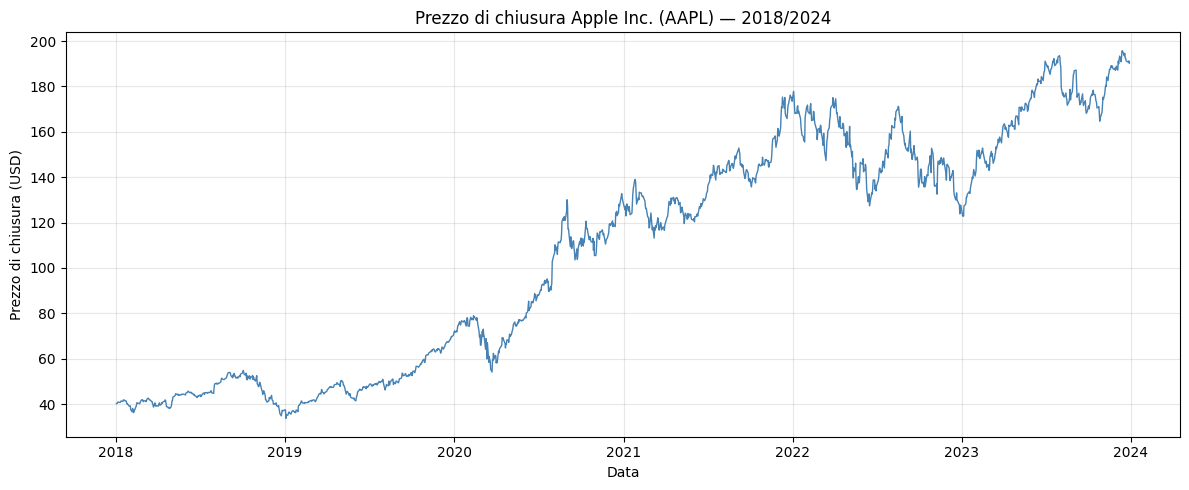

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(data['Close'], color='steelblue', linewidth=1)
plt.title('Prezzo di chiusura Apple Inc. (AAPL) — 2018/2024')
plt.xlabel('Data')
plt.ylabel('Prezzo di chiusura (USD)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('grafico_close_apple.png', dpi=300)
plt.show()

## Features

Per arricchire il dataset aggiungiamo alcune feature derivate. In particolare:

1. il rendimento giornaliero,
2. la media mobile a 10 giorni,
3. la media mobile a 50 giorni,
4. la volatilità a 10 giorni,
5. il momentum a 5 giorni.

Questi indicatori tecnici aiutano il modello a catturare meglio l’andamento del mercato.

In [6]:
# Rendimento giornaliero
data["Return"] = data["Close"].pct_change()

# Medie mobili
data["MA10"] = data["Close"].rolling(10).mean()
data["MA50"] = data["Close"].rolling(50).mean()

# Volatilità
data["Volatility"] = data["Return"].rolling(10).std()

# Momentum
data["Momentum"] = data["Close"] - data["Close"].shift(5)

## Creazione del target

La variabile target vale 1 se il prezzo di chiusura del giorno successivo è maggiore di quello corrente, e 0 altrimenti. In questo modo il problema viene formulato come classificazione binaria: prevedere se il titolo salirà o scenderà il giorno dopo.

In [7]:
data["Target"] = (data["Close"].shift(-1) > data["Close"]).astype(int)
data = data.dropna()
data.head()

Price,Close,High,Low,Open,Volume,Return,MA10,MA50,Volatility,Momentum,Target
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,,,,,,
Date,,,,,,,,,,,
2018-03-14,41.845676,42.333454,41.697935,42.286553,117473600,-0.008501,41.666980,40.322700,0.011184,0.799671,1
2018-03-15,41.894917,42.267788,41.758905,41.859742,90975200,0.001177,41.752575,40.355951,0.009289,0.400997,0
2018-03-16,41.747192,42.005150,41.653387,41.894930,157618800,-0.003526,41.795023,40.386387,0.009275,-0.459621,0
2018-03-19,41.109325,41.618208,40.724732,41.583033,133787200,-0.015279,41.759378,40.400330,0.010543,-1.505543,0
2018-03-20,41.095242,41.461074,41.024888,41.095242,78597600,-0.000343,41.725842,40.404788,0.010544,-1.109222,0


## Definizione di X e y

Definiamo la matrice delle feature X e il vettore target y. Oltre alle variabili originali del dataset, includiamo anche gli indicatori tecnici creati in precedenza.

In [8]:
features = ["Open", "High", "Low", "Close", "Volume", "Return", "MA10", "MA50", "Volatility", "Momentum"]

X = data[features]
y = data["Target"]

In [9]:
# Esperimento con sole feature derivate tramite feature engineering

features_derived = [
    "MA10",
    "MA50",
    "Volatility",
    "Momentum"
]

X_derived = data[features_derived]
y_derived = data["Target"]

# Suddivisione temporale train/test
split = int(len(X_derived) * 0.8)

X_train_der = X_derived.iloc[:split]
X_test_der = X_derived.iloc[split:]

y_train_der = y_derived.iloc[:split]
y_test_der = y_derived.iloc[split:]

print("Dimensione training set:", X_train_der.shape)
print("Dimensione test set:", X_test_der.shape)

Dimensione training set: (1168, 4)
Dimensione test set: (292, 4)


## Suddivisione train/test temporale

Poiché si tratta di una serie temporale, la divisione tra training set e test set viene effettuata rispettando l’ordine cronologico dei dati. Questa scelta è più corretta rispetto a una divisione casuale, che introdurrebbe informazioni future nel training

In [10]:
split = int(len(X) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

In [11]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

tscv = TimeSeriesSplit(n_splits=5)

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", random_state=42))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=tscv,
        scoring="accuracy"
    )

    results.append({
        "Model": name,
        "Accuracy media": scores.mean(),
        "Deviazione std": scores.std()
    })

cv_results = pd.DataFrame(results)

print(cv_results)

                    Model  Accuracy media  Deviazione std
0     Logistic Regression        0.482474        0.031202
1  Support Vector Machine        0.481443        0.028158
2           Random Forest        0.486598        0.031371


## Baseline semplice

Introduciamo una baseline molto semplice, che prevede sempre un rialzo del prezzo. Questo confronto è utile per verificare se i modelli di machine learning ottengono risultati realmente migliori di una strategia banale.

In [12]:
baseline_pred = np.ones(len(y_test), dtype=int)
baseline_accuracy = accuracy_score(y_test, baseline_pred)

print("Baseline accuracy:", baseline_accuracy)

Baseline accuracy: 0.5376712328767124


## Logistic Regression

Alleniamo un modello di Logistic Regression, uno dei metodi più semplici e interpretabili per problemi di classificazione binaria. Successivamente valutiamo la sua accuratezza sul test set.

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

log_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

log_model.fit(X_train, y_train)
log_pred = log_model.predict(X_test)

log_accuracy = accuracy_score(y_test, log_pred)

print("Accuracy Logistic Regression:", log_accuracy)

Accuracy Logistic Regression: 0.523972602739726


## Random Forest

Alleniamo anche un modello Random Forest, basato su un insieme di alberi decisionali. Questo approccio è spesso più flessibile della regressione logistica e può catturare relazioni non lineari tra le variabili.

In [14]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Accuracy Random Forest:", rf_accuracy)

Accuracy Random Forest: 0.4931506849315068


In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, f1_score

# Validazione temporale
tscv = TimeSeriesSplit(n_splits=5)

# Griglia parametri Random Forest
param_grid_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 3, 5, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "class_weight": [None, "balanced"]
}

rf_base = RandomForestClassifier(random_state=42)

grid_rf = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid_rf,
    cv=tscv,
    scoring="f1_weighted",
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

print("Migliori parametri Random Forest:")
print(grid_rf.best_params_)

print("\nMiglior score in validazione:")
print(grid_rf.best_score_)

# Modello finale ottimizzato
rf_model = grid_rf.best_estimator_

rf_pred = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)

print("\nAccuracy Random Forest ottimizzata:", rf_accuracy)
print("\nClassification report Random Forest ottimizzata:")
print(classification_report(y_test, rf_pred, zero_division=0))

Migliori parametri Random Forest:
{'class_weight': None, 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 300}

Miglior score in validazione:
0.45967159143317715

Accuracy Random Forest ottimizzata: 0.4965753424657534

Classification report Random Forest ottimizzata:
              precision    recall  f1-score   support

           0       0.47      0.70      0.56       135
           1       0.55      0.32      0.41       157

    accuracy                           0.50       292
   macro avg       0.51      0.51      0.49       292
weighted avg       0.52      0.50      0.48       292



## Suport Vector Machine

Addestriamo un modello SVM con kernel RBF, particolarmente adatto 
quando i dati non sono linearmente separabili. Prima dell'addestramento 
le feature vengono normalizzate tramite StandardScaler, 
necessario per le prestazioni ottimali della SVM.

In [16]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Normalizzazione delle feature
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Kernel da confrontare
kernels = {
    "Linear": SVC(kernel="linear", random_state=42),
    "Polynomial": SVC(kernel="poly", degree=3, random_state=42),
    "RBF": SVC(kernel="rbf", random_state=42),
    "Sigmoid": SVC(kernel="sigmoid", random_state=42)
}

results = []

# Addestramento e valutazione
for name, model in kernels.items():

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    results.append({
        "Kernel": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0)
    })

# Tabella riassuntiva
svm_results = pd.DataFrame(results)

print("Confronto tra i kernel della SVM:")
print(svm_results)

# Individuazione del miglior kernel
best_kernel = svm_results.loc[svm_results["Accuracy"].idxmax(), "Kernel"]
best_accuracy = svm_results["Accuracy"].max()

print(f"\nMiglior kernel: {best_kernel}")
print(f"Accuracy: {best_accuracy:.4f}")

# Addestramento finale del modello migliore
if best_kernel == "Polynomial":
    svm_model = SVC(kernel="poly", degree=3, random_state=42)
elif best_kernel == "Linear":
    svm_model = SVC(kernel="linear", random_state=42)
elif best_kernel == "Sigmoid":
    svm_model = SVC(kernel="sigmoid", random_state=42)
else:
    svm_model = SVC(kernel="rbf", random_state=42)

svm_model.fit(X_train_scaled, y_train)

svm_pred = svm_model.predict(X_test_scaled)
svm_accuracy = accuracy_score(y_test, svm_pred)

print(f"\nAccuracy finale della SVM ({best_kernel}): {svm_accuracy:.4f}")

Confronto tra i kernel della SVM:
       Kernel  Accuracy  Precision    Recall  F1-score
0      Linear  0.534247   0.536082  0.993631  0.696429
1  Polynomial  0.500000   0.540146  0.471338  0.503401
2         RBF  0.496575   0.578125  0.235669  0.334842
3     Sigmoid  0.503425   0.524793  0.808917  0.636591

Miglior kernel: Linear
Accuracy: 0.5342

Accuracy finale della SVM (Linear): 0.5342


In [17]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Validazione temporale
tscv = TimeSeriesSplit(n_splits=5)

# Griglia parametri SVM
param_grid = {
    "kernel": ["linear", "rbf", "poly"],
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", 0.01, 0.1, 1],
    "degree": [2, 3]
}

grid_svm = GridSearchCV(
    estimator=SVC(random_state=42),
    param_grid=param_grid,
    cv=tscv,
    scoring="f1_weighted",
    n_jobs=-1
)

grid_svm.fit(X_train_scaled, y_train)

print("Migliori parametri SVM:")
print(grid_svm.best_params_)

print("\nMiglior score in validazione:")
print(grid_svm.best_score_)

# Modello finale ottimizzato
svm_model = grid_svm.best_estimator_

svm_pred = svm_model.predict(X_test_scaled)
svm_accuracy = accuracy_score(y_test, svm_pred)

print("\nAccuracy SVM ottimizzata:", svm_accuracy)
print("\nClassification report SVM ottimizzata:")
print(classification_report(y_test, svm_pred, zero_division=0))

Migliori parametri SVM:
{'C': 10, 'degree': 2, 'gamma': 0.1, 'kernel': 'rbf'}

Miglior score in validazione:
0.5067443231026988

Accuracy SVM ottimizzata: 0.4965753424657534

Classification report SVM ottimizzata:
              precision    recall  f1-score   support

           0       0.47      0.79      0.59       135
           1       0.57      0.25      0.35       157

    accuracy                           0.50       292
   macro avg       0.52      0.52      0.47       292
weighted avg       0.53      0.50      0.46       292



## Rete Neurale Ricorrente (LSTM)

Addestriamo una rete LSTM per sfruttare le dipendenze temporali 
presenti nei dati finanziari. I dati vengono prima normalizzati 
e poi riorganizzati in sequenze temporali di 10 giorni, 
che rappresentano l'input della rete.

In [18]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.preprocessing import StandardScaler

# Normalizzazione corretta: fit solo sul training set
lstm_scaler = StandardScaler()

X_train_s = lstm_scaler.fit_transform(X_train)
X_test_s = lstm_scaler.transform(X_test)

# Creazione sequenze temporali
def create_sequences(X, y, seq_len=10):
    Xs, ys = [], []
    for i in range(len(X) - seq_len):
        Xs.append(X[i:i+seq_len])
        ys.append(y.iloc[i+seq_len])
    return np.array(Xs), np.array(ys)

seq_len = 10

X_train_seq, y_train_seq = create_sequences(X_train_s, y_train, seq_len)
X_test_seq, y_test_seq = create_sequences(X_test_s, y_test, seq_len)

# Architettura LSTM
lstm_model = Sequential([
    LSTM(64, input_shape=(seq_len, X_train_seq.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

lstm_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

lstm_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=20,
    batch_size=32,
    verbose=1
)

lstm_pred_prob = lstm_model.predict(X_test_seq)
lstm_pred = (lstm_pred_prob > 0.5).astype(int).flatten()

lstm_accuracy = accuracy_score(y_test_seq, lstm_pred)

print("Accuracy LSTM:", lstm_accuracy)

C:\Users\ricca\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.5302 - loss: 0.6942
Epoch 2/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5389 - loss: 0.6915
Epoch 3/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5276 - loss: 0.6908
Epoch 4/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5380 - loss: 0.6890
Epoch 5/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5501 - loss: 0.6894
Epoch 6/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5268 - loss: 0.6890
Epoch 7/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5380 - loss: 0.6885
Epoch 8/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5656 - loss: 0.6843
Epoch 9/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5544 - loss: 0.6837
Epoch 10/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5630 - loss: 0.6847
Epoch 11/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5622 - loss: 0.6807
Epoch 12/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5838 - lo

In [19]:
print("Shape X_train_seq:", X_train_seq.shape)
print("Shape X_test_seq:", X_test_seq.shape)
lstm_model.summary()

Shape X_train_seq: (1158, 10, 10)
Shape X_test_seq: (282, 10, 10)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        19,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 63,941 (249.77 KB)

 Trainable params: 21,313 (83.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 42,628 (166.52 KB)

## Confronto dei risultati

Visualizziamo in un grafico le accuracy ottenute dai diversi approcci, in modo da confrontare immediatamente le performance dei modelli rispetto alla baseline.

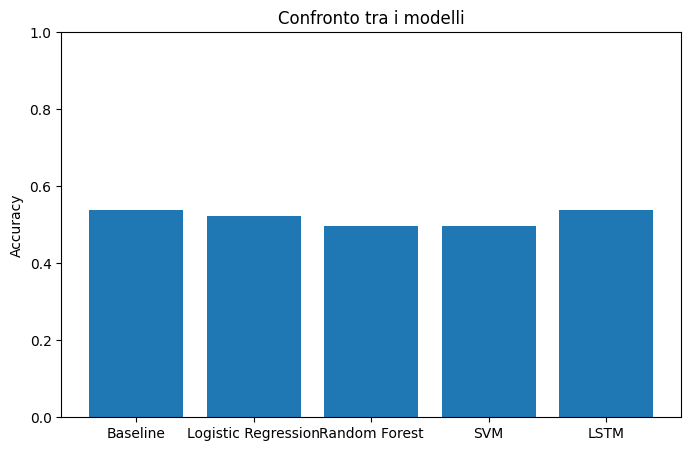

In [20]:
models = ["Baseline", "Logistic Regression", "Random Forest", "SVM", "LSTM"]
scores = [baseline_accuracy, log_accuracy, rf_accuracy, svm_accuracy, lstm_accuracy]

plt.figure(figsize=(8,5))
plt.bar(models, scores)
plt.ylabel("Accuracy")
plt.title("Confronto tra i modelli")
plt.ylim(0, 1)
plt.show()

## Confusion matrix

Le confusion matrix permettono di osservare in modo più dettagliato il comportamento dei modelli, mostrando quante volte la previsione è corretta o errata per ciascuna classe.

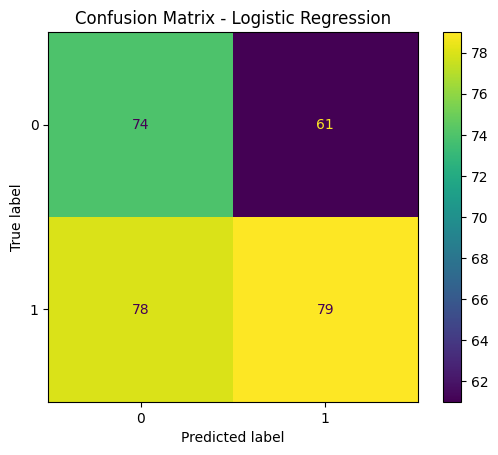

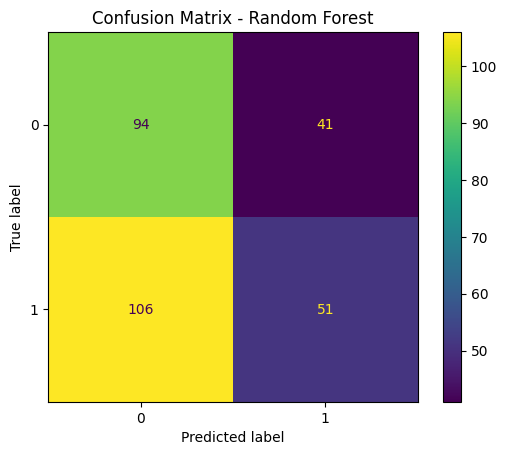

In [21]:
ConfusionMatrixDisplay.from_predictions(y_test, log_pred)
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

ConfusionMatrixDisplay.from_predictions(y_test, rf_pred)
plt.title("Confusion Matrix - Random Forest")
plt.show()

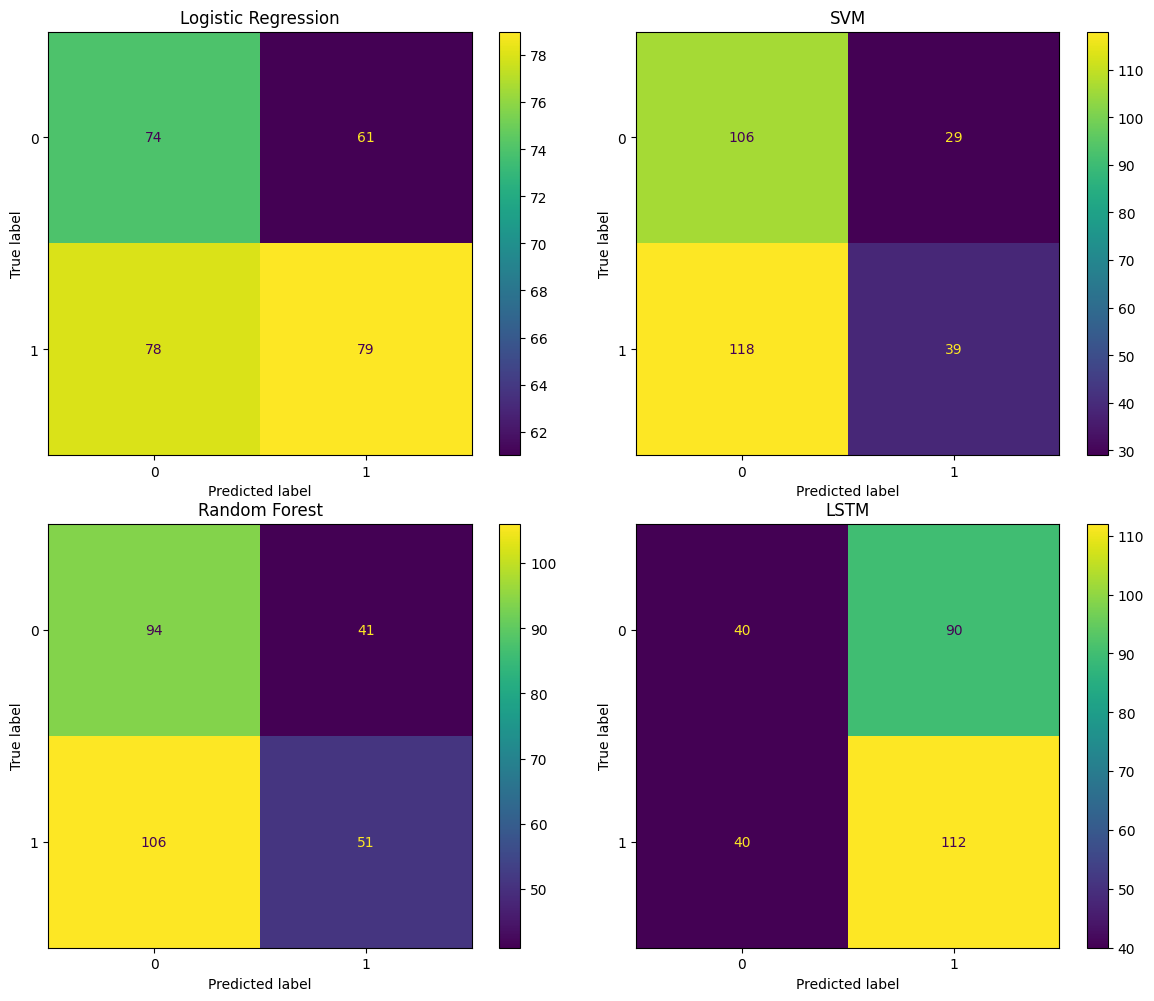

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(y_test, log_pred, ax=axes[0,0])
axes[0,0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(y_test, svm_pred, ax=axes[0,1])
axes[0,1].set_title("SVM")

ConfusionMatrixDisplay.from_predictions(y_test, rf_pred, ax=axes[1,0])
axes[1,0].set_title("Random Forest")

ConfusionMatrixDisplay.from_predictions(y_test_seq, lstm_pred, ax=axes[1,1])
axes[1,1].set_title("LSTM")

plt.tight_layout()
plt.show()

In [23]:
from sklearn.metrics import classification_report

print(classification_report(y_test, baseline_pred))

print("=== Logistic Regression ===")
print(classification_report(y_test, log_pred))

print("=== SVM ===")
print(classification_report(y_test, svm_pred))

print("=== Random Forest ===")
print(classification_report(y_test, rf_pred))

print("=== LSTM ===")
print(classification_report(y_test_seq, lstm_pred))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00       135
           1       0.54      1.00      0.70       157

    accuracy                           0.54       292
   macro avg       0.27      0.50      0.35       292
weighted avg       0.29      0.54      0.38       292

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.49      0.55      0.52       135
           1       0.56      0.50      0.53       157

    accuracy                           0.52       292
   macro avg       0.53      0.53      0.52       292
weighted avg       0.53      0.52      0.52       292

=== SVM ===
              precision    recall  f1-score   support

           0       0.47      0.79      0.59       135
           1       0.57      0.25      0.35       157

    accuracy                           0.50       292
   macro avg       0.52      0.52      0.47       292
weighted avg       0.53      0.50 

C:\Users\ricca\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ricca\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ricca\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capital

## Classification report

Il classification report riassume precision, recall e F1-score, offrendo una valutazione più completa rispetto alla sola accuracy.

In [24]:
print("Logistic Regression")
print(classification_report(y_test, log_pred))

print("Random Forest")
print(classification_report(y_test, rf_pred))

Logistic Regression
              precision    recall  f1-score   support

           0       0.49      0.55      0.52       135
           1       0.56      0.50      0.53       157

    accuracy                           0.52       292
   macro avg       0.53      0.53      0.52       292
weighted avg       0.53      0.52      0.52       292

Random Forest
              precision    recall  f1-score   support

           0       0.47      0.70      0.56       135
           1       0.55      0.32      0.41       157

    accuracy                           0.50       292
   macro avg       0.51      0.51      0.49       292
weighted avg       0.52      0.50      0.48       292



## Predizione di prezzi tramite la Random Forest

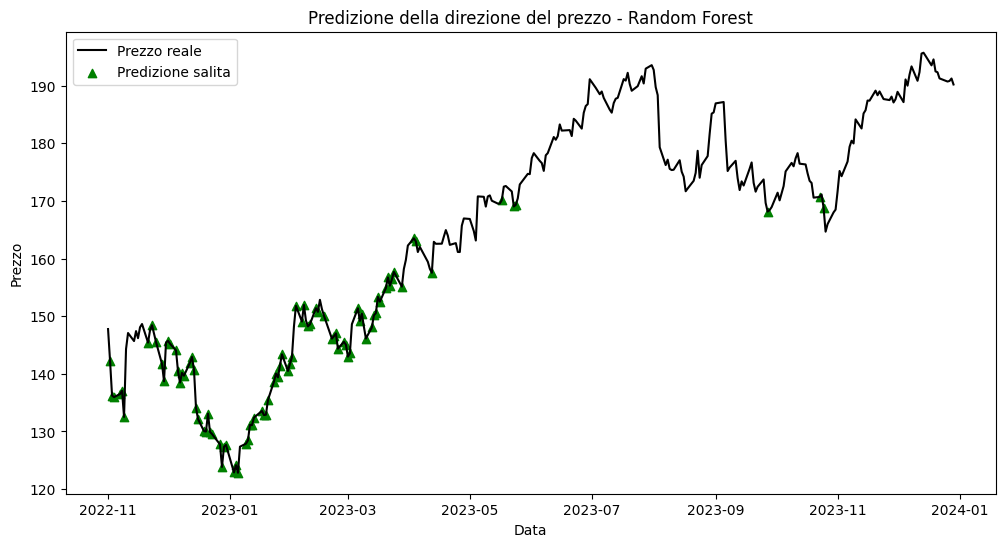

In [25]:
results = data.iloc[split:].copy()
results["Prediction"] = rf_pred

plt.figure(figsize=(12,6))

plt.plot(results.index, results["Close"], label="Prezzo reale", color="black")

buy_signals = results[results["Prediction"] == 1]

plt.scatter(buy_signals.index, buy_signals["Close"],
            color="green", label="Predizione salita", marker="^")

plt.title("Predizione della direzione del prezzo - Random Forest")
plt.xlabel("Data")
plt.ylabel("Prezzo")
plt.legend()

plt.show()

## Grafico predizioni

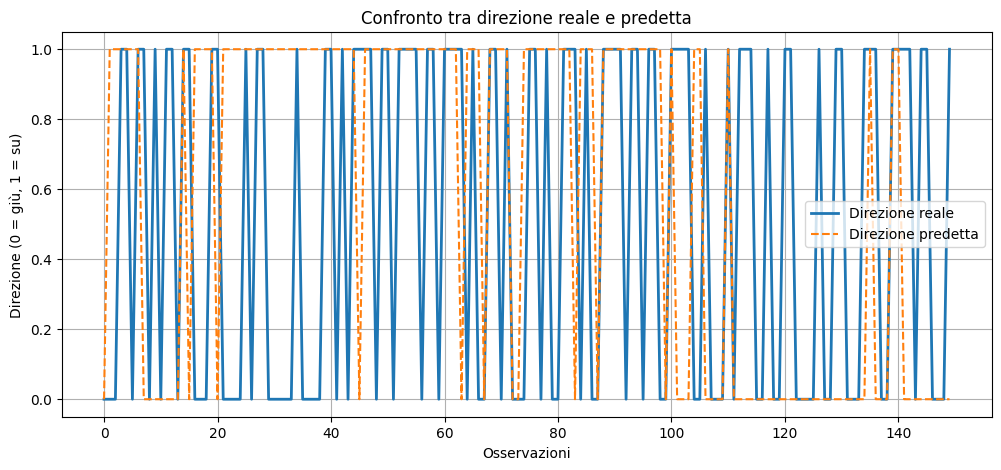

In [26]:
plt.figure(figsize=(12,5))

plt.plot(y_test.values[:150], label="Direzione reale", linewidth=2)
plt.plot(rf_pred[:150], label="Direzione predetta", linestyle="--")

plt.title("Confronto tra direzione reale e predetta")
plt.xlabel("Osservazioni")
plt.ylabel("Direzione (0 = giù, 1 = su)")

plt.legend()
plt.grid(True)

plt.show()

In [32]:
rf_pred = rf_model.predict(X_test)


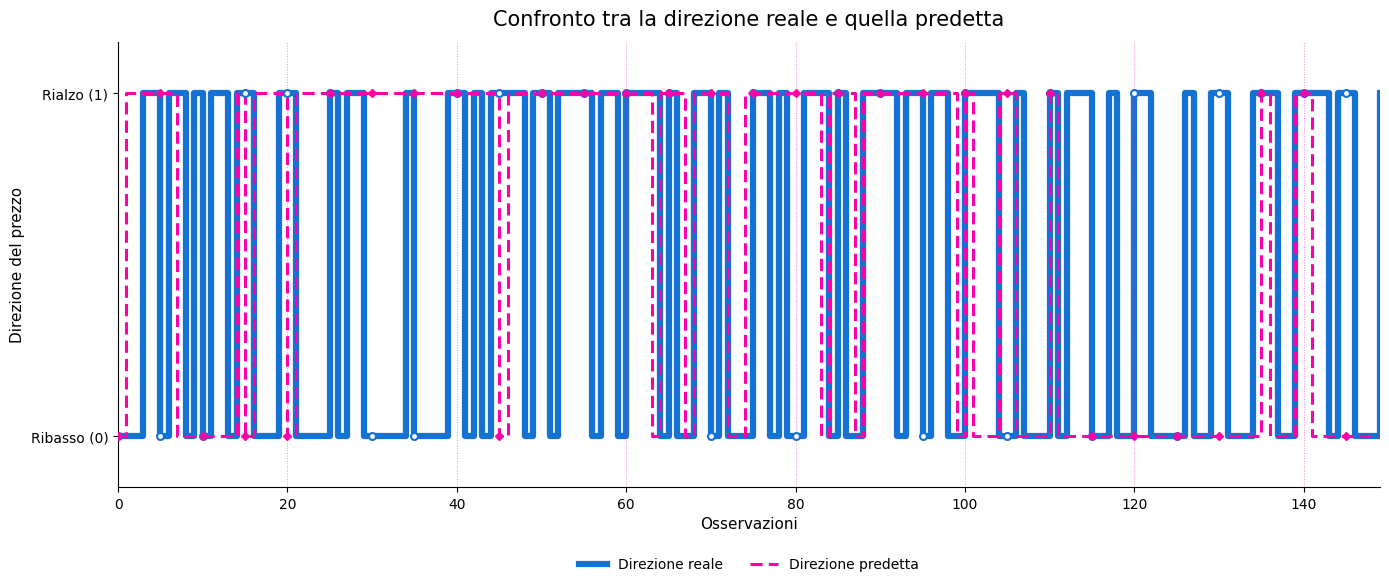

In [42]:
import numpy as np
import matplotlib.pyplot as plt

# Numero di osservazioni da visualizzare
n_osservazioni = 150

# Valori reali e predizioni della Random Forest
y_reale = np.asarray(y_test)[:n_osservazioni]
y_predetta = np.asarray(rf_pred)[:n_osservazioni]

# Asse delle osservazioni
x = np.arange(n_osservazioni)

# Creazione del grafico
fig, ax = plt.subplots(figsize=(14, 6))

# Direzione reale: linea blu scuro, continua e spessa
ax.step(
    x,
    y_reale,
    where="post",
    color="#1572D5",
    linewidth=4.5,
    linestyle="-",
    label="Direzione reale",
    zorder=1
)

# Direzione predetta: linea rossa, tratteggiata e più sottile
ax.step(
    x,
    y_predetta,
    where="post",
    color="#FF00A6",
    linewidth=2.2,
    linestyle=(0, (4, 2)),
    label="Direzione predetta",
    zorder=2
)

# Marcatori inseriti ogni 5 osservazioni
ax.plot(
    x,
    y_reale,
    color="#1572D5",
    marker="o",
    markersize=5,
    markerfacecolor="white",
    markeredgewidth=1.5,
    linestyle="none",
    markevery=5,
    zorder=3
)

ax.plot(
    x,
    y_predetta,
    color="#FF00A6",
    marker="D",
    markersize=4,
    linestyle="none",
    markevery=5,
    zorder=4
)

# Titolo ed etichette
ax.set_title(
    "Confronto tra la direzione reale e quella predetta",
    fontsize=15,
    pad=12
)

ax.set_xlabel("Osservazioni", fontsize=11)
ax.set_ylabel("Direzione del prezzo", fontsize=11)

ax.set_yticks([0, 1])
ax.set_yticklabels(["Ribasso (0)", "Rialzo (1)"])

ax.set_ylim(-0.15, 1.15)
ax.set_xlim(0, n_osservazioni - 1)

# Griglia leggera
ax.grid(
    axis="x",
    color="#FF00A6",
    linestyle=":",
    linewidth=0.7,
    alpha=0.5
)

# Legenda esterna per non coprire le linee
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=2,
    frameon=False
)

# Rimozione dei bordi superiore e destro
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Salvataggio ad alta risoluzione
plt.savefig(
    "confronto_direzione_reale_predetta.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

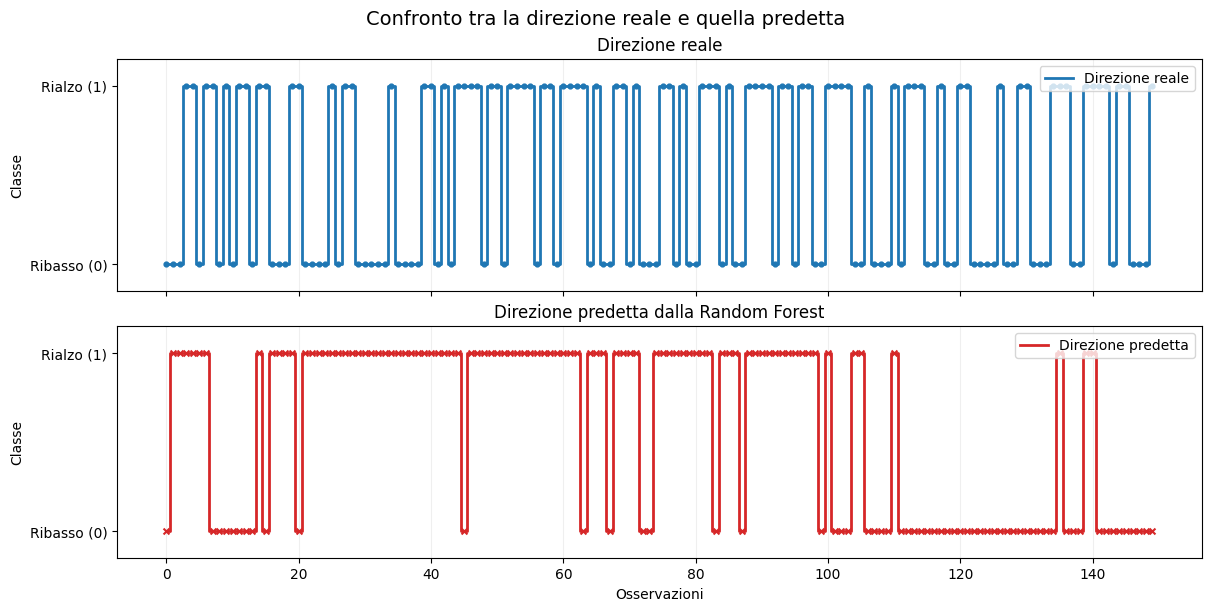

In [43]:
import numpy as np
import matplotlib.pyplot as plt

# Numero di osservazioni da visualizzare
n_osservazioni = 150

# Valori reali e predizioni della Random Forest
y_reale = np.asarray(y_test)[:n_osservazioni]
y_predetta = np.asarray(rf_pred)[:n_osservazioni]

# Asse delle osservazioni
x = np.arange(n_osservazioni)

# Creazione dei due grafici
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 6),
    sharex=True,
    constrained_layout=True
)

# Grafico della direzione reale
axes[0].step(
    x,
    y_reale,
    where="mid",
    color="#1f77b4",
    linewidth=2,
    label="Direzione reale"
)

axes[0].scatter(
    x,
    y_reale,
    color="#1f77b4",
    s=12,
    zorder=3
)

axes[0].set_title("Direzione reale")
axes[0].set_ylabel("Classe")
axes[0].set_yticks([0, 1])
axes[0].set_yticklabels(["Ribasso (0)", "Rialzo (1)"])
axes[0].set_ylim(-0.15, 1.15)
axes[0].grid(axis="x", alpha=0.2)
axes[0].legend(loc="upper right")

# Grafico della direzione predetta
axes[1].step(
    x,
    y_predetta,
    where="mid",
    color="#d62728",
    linewidth=2,
    label="Direzione predetta"
)

axes[1].scatter(
    x,
    y_predetta,
    color="#d62728",
    marker="x",
    s=18,
    zorder=3
)

axes[1].set_title("Direzione predetta dalla Random Forest")
axes[1].set_xlabel("Osservazioni")
axes[1].set_ylabel("Classe")
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(["Ribasso (0)", "Rialzo (1)"])
axes[1].set_ylim(-0.15, 1.15)
axes[1].grid(axis="x", alpha=0.2)
axes[1].legend(loc="upper right")

# Titolo complessivo
fig.suptitle(
    "Confronto tra la direzione reale e quella predetta",
    fontsize=14
)

# Salvataggio ad alta risoluzione
plt.savefig(
    "confronto_direzione_reale_predetta.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Return        0.172284
Open          0.104728
MA50          0.103053
High          0.100609
MA10          0.099002
Volatility    0.091249
Momentum      0.090638
Volume        0.088302
Close         0.076024
Low           0.074111
dtype: float64


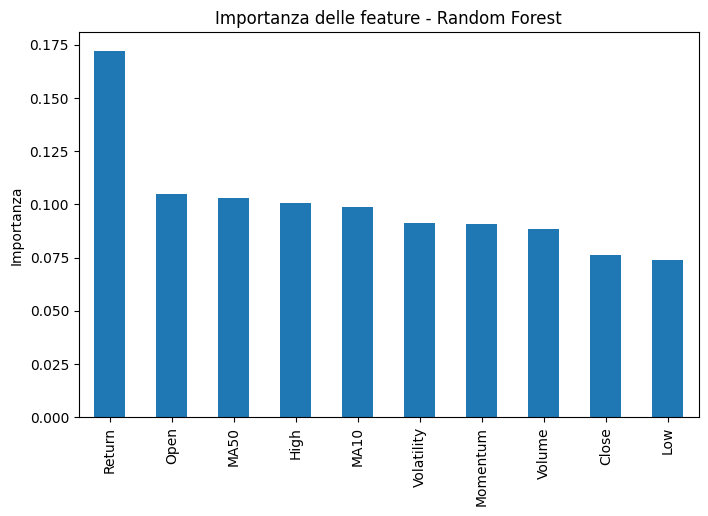

In [27]:
importances = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=False)

print(importances)

plt.figure(figsize=(8,5))
importances.plot(kind="bar")
plt.title("Importanza delle feature - Random Forest")
plt.ylabel("Importanza")
plt.show()

## Analisi dell'impatto del feature engineering

In questa sezione confrontiamo le performance dei modelli addestrati 
con tutte le feature (originali + indicatori tecnici) rispetto a quelli 
addestrati usando solo le variabili originali del dataset.

In [28]:
# Esperimento senza feature engineering - solo prezzi originali
features_base = ['Open', 'High', 'Low', 'Close', 'Volume']

X_base = data[features_base]
y_base = data['Target']

# Stesso split temporale 80/20
split_base = int(len(X_base) * 0.8)
X_train_base = X_base.iloc[:split_base]
X_test_base = X_base.iloc[split_base:]
y_train_base = y_base.iloc[:split_base]
y_test_base = y_base.iloc[split_base:]

# Logistic Regression senza feature engineering
log_base = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

log_base.fit(X_train_base, y_train_base)
log_base_pred = log_base.predict(X_test_base)
log_base_acc = accuracy_score(y_test_base, log_base_pred)

# Random Forest senza feature engineering
rf_base = RandomForestClassifier(n_estimators=100, random_state=42)
rf_base.fit(X_train_base, y_train_base)
rf_base_pred = rf_base.predict(X_test_base)
rf_base_acc = accuracy_score(y_test_base, rf_base_pred)

# SVM senza feature engineering
scaler_base = StandardScaler()
X_train_base_scaled = scaler_base.fit_transform(X_train_base)
X_test_base_scaled = scaler_base.transform(X_test_base)
svm_base = SVC(kernel='rbf', random_state=42)
svm_base.fit(X_train_base_scaled, y_train_base)
svm_base_pred = svm_base.predict(X_test_base_scaled)
svm_base_acc = accuracy_score(y_test_base, svm_base_pred)

print("=== Senza feature engineering (solo prezzi originali) ===")
print(f"Logistic Regression: {log_base_acc:.4f}")
print(f"Random Forest:       {rf_base_acc:.4f}")
print(f"SVM:                 {svm_base_acc:.4f}")

print("\n=== Con feature engineering (tutti gli indicatori) ===")
print(f"Logistic Regression: {log_accuracy:.4f}")
print(f"Random Forest:       {rf_accuracy:.4f}")
print(f"SVM:                 {svm_accuracy:.4f}")

=== Senza feature engineering (solo prezzi originali) ===
Logistic Regression: 0.4932
Random Forest:       0.5103
SVM:                 0.4829

=== Con feature engineering (tutti gli indicatori) ===
Logistic Regression: 0.5240
Random Forest:       0.4966
SVM:                 0.4966


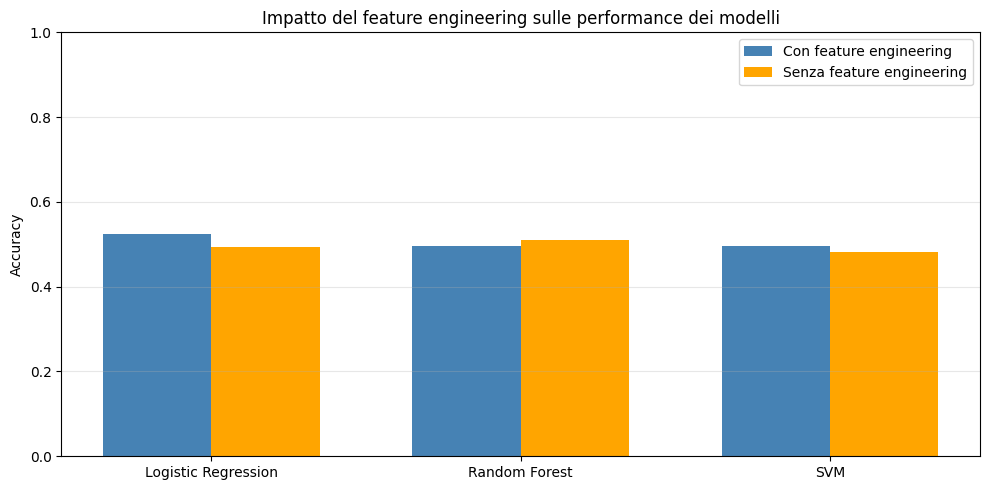

In [29]:
# Grafico confronto con e senza feature engineering
labels = ['Logistic Regression', 'Random Forest', 'SVM']
scores_with = [log_accuracy, rf_accuracy, svm_accuracy]
scores_without = [log_base_acc, rf_base_acc, svm_base_acc]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, scores_with, width, label='Con feature engineering', color='steelblue')
bars2 = ax.bar(x + width/2, scores_without, width, label='Senza feature engineering', color='orange')

ax.set_ylabel('Accuracy')
ax.set_title('Impatto del feature engineering sulle performance dei modelli')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.set_ylim(0, 1)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('feature_engineering_comparison.png', dpi=300)
plt.show()

## Conclusioni

In questo modello ho applicato algoritmi di Machine Learning per predire la direzione del prezzo di un'azione utilizzando i dati storici.

Ho confrontato la Logistic Regression e Random Forest, osservando che Random Forest offre performance migliori.

Questo dimostra come il Machine Learning possa essere applicato all'analisi dei mercati finanziari, pur con alcune limitazioni
dovute alla natura complessa dei mercati.